# Práctica de Campo N.º 5 — Semana 5
## Comparación de modelos supervisados para la clasificación y priorización de reportes ciudadanos

**Curso:** Sistemas Inteligentes y Machine Learning — UPN
**Docente:** Dr. Víctor Jaime Polo Romero
**Integrantes:** Azcarate Noriega, Miguel Alonso · Candiotti Arancibia, Renzo · Del Portal Quevedo de la Cruz, Augusto · Arteaga Sánchez, Heyner Jhonel

---

### Qué hace este notebook

Continúa el modelo del agente definido en la Práctica de Campo 2. Allí se especificó un agente que recibe un reporte ciudadano en texto libre y debe decidir dos cosas: **a qué gerencia municipal corresponde** (Modelo A) y **con qué urgencia atenderlo** (Modelo B).

Aquí se construye y se evalúa esa capa de aprendizaje:

1. Carga y limpieza del corpus
2. Análisis exploratorio (EDA) con gráficos
3. Vectorización del texto con TF-IDF
4. Entrenamiento de **dos modelos supervisados** por cada tarea: Naive Bayes y Regresión Logística
5. Comparación con métricas, matriz de confusión y validación cruzada
6. Análisis de errores
7. Aplicación de la capa de reglas de producción sobre la salida de los modelos

### Metas declaradas en la PC2

| Métrica | Meta |
|---|---|
| F1 macro en categoría | ≥ 0,75 |
| Recall en prioridad alta | ≥ 0,90 |

### Nota sobre el corpus

El corpus es de **elaboración propia**. Ante la inexistencia de un repositorio público y estructurado de reportes ciudadanos de la Municipalidad Provincial de Trujillo, el equipo redactó 500 reportes simulados que replican el registro informal, los errores de tipeo y la taxonomía de categorías descritos en la PC2. El script generador se entrega junto a este notebook, de modo que el corpus es reproducible.

---
## 1. Preparación del entorno

Todas las librerías vienen preinstaladas en Google Colab. No hace falta instalar nada.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata, re

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, recall_score, precision_score, accuracy_score)

SEMILLA = 42                      # fija el azar: cualquiera que corra esto obtiene lo mismo
np.random.seed(SEMILLA)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
sns.set_palette("deep")

print("Entorno listo")

Entorno listo


---
## 2. Carga del corpus

La celda funciona tanto si el archivo está junto al notebook como si hay que subirlo a Colab.

In [2]:
import os

RUTA = "reportes_ciudadanos_trujillo_2026.csv"

if not os.path.exists(RUTA):
    try:                                   # estamos en Colab: pedir el archivo
        from google.colab import files
        subidos = files.upload()
        RUTA = list(subidos.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"No se encontro {RUTA}. Colocalo junto al notebook.")

df = pd.read_csv(RUTA)
print(f"Registros cargados: {len(df)}")
print(f"Columnas: {list(df.columns)}")
df.head(5)

Registros cargados: 500
Columnas: ['id_reporte', 'texto_reporte', 'canal', 'zona', 'longitud_texto', 'menciona_riesgo', 'menciona_menores', 'dias_transcurridos', 'fecha_reporte', 'anotador', 'categoria', 'prioridad']


,id_reporte,texto_reporte,canal,zona,longitud_texto,menciona_riesgo,menciona_menores,dias_transcurridos,fecha_reporte,anotador,categoria,prioridad
0,1,"BUEN DIA, EL SARDINEL DE URB. SANTA MARIA ESTÁ...",app_municipal,Trujillo - cercado,35,0,0,20,2026-01-21,H. Arteaga,C1 Vias y veredas,baja
1,2,quiero reportar que las veredas de Monserrate ...,x,Trujillo - cercado,14,0,0,5,2026-07-10,A. Del Portal,C1 Vias y veredas,alta
2,3,hay un problema serio en Rio Seco,libro_reclamaciones,El Porvenir,7,0,0,5,2025-11-06,R. Candiotti,C1 Vias y veredas,baja
3,4,"LA BERMA DE EL MERCADO ESTA DESTROZADA, NO SE ...",libro_reclamaciones,Florencia de Mora,20,0,1,12,2026-01-17,H. Arteaga,C1 Vias y veredas,alta
4,5,xfa el pasaje de Las Delicias sigue sin asfalt...,app_municipal,Moche,23,0,1,8,2026-04-16,H. Arteaga,C1 Vias y veredas,media


### 2.1. Revisión inicial de la estructura

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id_reporte          500 non-null    int64
 1   texto_reporte       500 non-null    str  
 2   canal               500 non-null    str  
 3   zona                500 non-null    str  
 4   longitud_texto      500 non-null    int64
 5   menciona_riesgo     500 non-null    int64
 6   menciona_menores    500 non-null    int64
 7   dias_transcurridos  500 non-null    int64
 8   fecha_reporte       500 non-null    str  
 9   anotador            500 non-null    str  
 10  categoria           500 non-null    str  
 11  prioridad           500 non-null    str  
dtypes: int64(5), str(7)
memory usage: 47.0 KB


In [4]:
print("Valores nulos por columna:")
print(df.isnull().sum())
print(f"\nReportes duplicados (texto identico): {df.texto_reporte.duplicated().sum()}")
print(f"\nEstadisticos de las variables numericas:")
df[["longitud_texto", "dias_transcurridos", "menciona_riesgo", "menciona_menores"]].describe().round(2)

Valores nulos por columna:
id_reporte            0
texto_reporte         0
canal                 0
zona                  0
longitud_texto        0
menciona_riesgo       0
menciona_menores      0
dias_transcurridos    0
fecha_reporte         0
anotador              0
categoria             0
prioridad             0
dtype: int64

Reportes duplicados (texto identico): 1

Estadisticos de las variables numericas:


,longitud_texto,dias_transcurridos,menciona_riesgo,menciona_menores
count,500.00,500.00,500.0,500.00
mean,19.36,10.93,0.2,0.19
std,6.58,13.42,0.4,0.39
min,3.00,0.00,0.0,0.00
25%,16.00,2.00,0.0,0.00
50%,19.00,5.00,0.0,0.00
75%,23.00,12.00,0.0,0.00
max,43.00,60.00,1.0,1.00


---
## 3. Limpieza y normalización del texto

Un clasificador trata `Bache`, `bache` y `BACHE` como tres palabras distintas. La normalización las unifica para que el vocabulario no se infle sin necesidad. El proceso, tal como se definió en la PC2:

1. Pasar todo a minúsculas
2. Quitar tildes (el corpus real las usa de forma irregular)
3. Eliminar signos de puntuación y números
4. Eliminar palabras vacías (*stopwords*): `el`, `la`, `de`, `que`… que aparecen en todos los reportes y no distinguen ninguna categoría
5. Colapsar espacios múltiples

El texto original **no se descarta**: se guarda en una columna aparte para poder leer los casos mal clasificados en el análisis de errores.

In [5]:
# Palabras vacias del español. Se define a mano para no depender de descargas externas.
STOPWORDS_ES = set("""
a al algo algunas algunos ante antes como con contra cual cuando de del desde donde dos el
ella ellas ellos en entre era erais eran eras eres es esa esas ese eso esos esta estaba
estado estamos estan estar estas este esto estos estoy fue fueron fui ha habia han hasta hay
la las le les lo los mas me mi mia mientras mucho muy nada ni no nos nosotros o os otra otro
para pero poco por porque que quien se ser si sin sobre solo son su sus tambien tanto te
tiene tienen todo todos tu tus un una uno unos usted ustedes ya yo aqui ahi alli asi
""".split())

def normalizar(texto):
    """Devuelve el texto en minusculas, sin tildes, sin signos y sin palabras vacias."""
    texto = str(texto).lower()
    # quitar tildes y diacriticos
    texto = "".join(ch for ch in unicodedata.normalize("NFD", texto)
                    if unicodedata.category(ch) != "Mn")
    # dejar solo letras y la ñ
    texto = re.sub(r"[^a-zñ\s]", " ", texto)
    # quitar palabras vacias y palabras de una sola letra
    palabras = [p for p in texto.split() if p not in STOPWORDS_ES and len(p) > 1]
    return " ".join(palabras)

df["texto_limpio"] = df.texto_reporte.apply(normalizar)

# Comparacion antes / despues
ejemplo = df.sample(3, random_state=SEMILLA)
for _, fila in ejemplo.iterrows():
    print("ORIGINAL :", fila.texto_reporte)
    print("LIMPIO   :", fila.texto_limpio)
    print("-" * 100)

ORIGINAL : por favor hay papeles y botellas regados en Liberacion Social ya reclamamos varias veces!!
LIMPIO   : favor papeles botellas regados liberacion social reclamamos varias veces
----------------------------------------------------------------------------------------------------
ORIGINAL : reitero mi reclamo, la pista de Husares de Junin esta parchada por todos lados, parece trocha atiendan por favor...
LIMPIO   : reitero reclamo pista husares junin parchada lados parece trocha atiendan favor
----------------------------------------------------------------------------------------------------
ORIGINAL : xfa quedaron restos de poda en la acera de la plaza de Laredo por favor atiendan... y ademas las luminarias de la av. Trujillo no encienden
LIMPIO   : xfa quedaron restos poda acera plaza laredo favor atiendan ademas luminarias av trujillo encienden
----------------------------------------------------------------------------------------------------


In [6]:
# Impacto de la limpieza sobre el tamaño del vocabulario
vocab_original = set(" ".join(df.texto_reporte.str.lower()).split())
vocab_limpio   = set(" ".join(df.texto_limpio).split())

print(f"Palabras distintas antes de limpiar : {len(vocab_original)}")
print(f"Palabras distintas despues de limpiar: {len(vocab_limpio)}")
print(f"Reduccion: {100 * (1 - len(vocab_limpio)/len(vocab_original)):.1f}%")

Palabras distintas antes de limpiar : 823
Palabras distintas despues de limpiar: 527
Reduccion: 36.0%


---
## 4. Análisis exploratorio de datos (EDA)

Antes de entrenar hay que mirar los datos. Lo que se busca aquí es responder tres preguntas: ¿están balanceadas las clases?, ¿el corpus cubre toda la ciudad o solo algunas zonas?, y ¿hay señales evidentes que separen las clases?

### 4.1. Distribución de las variables objetivo

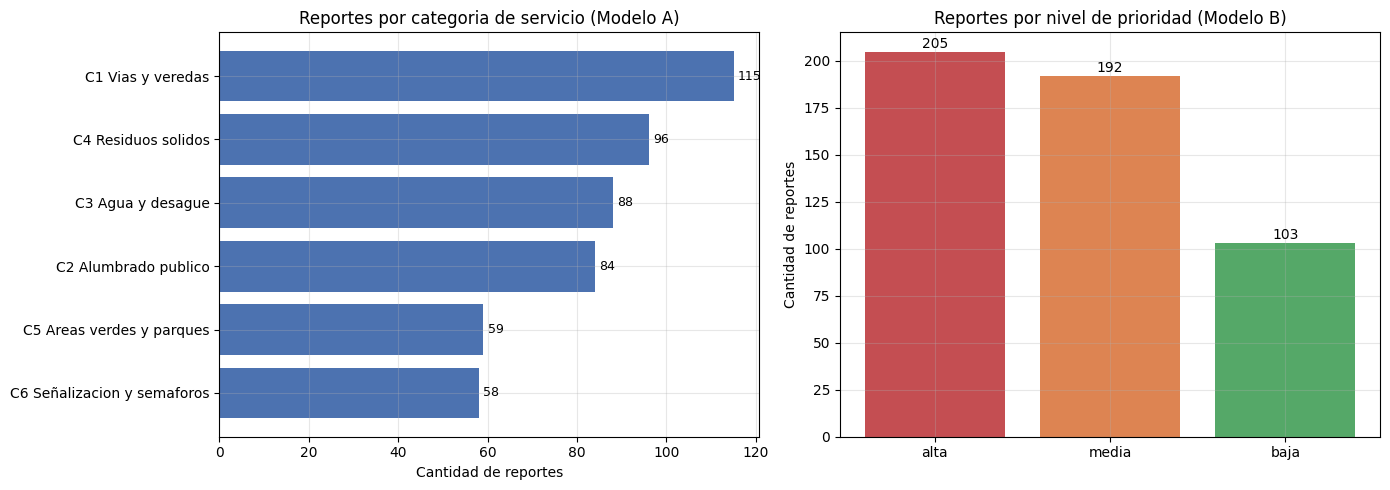

Desbalance en categoria:
categoria
C1 Vias y veredas              23.0
C4 Residuos solidos            19.2
C3 Agua y desague              17.6
C2 Alumbrado publico           16.8
C5 Areas verdes y parques      11.8
C6 Señalizacion y semaforos    11.6 

Desbalance en prioridad:
prioridad
alta     41.0
media    38.4
baja     20.6


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

conteo_cat = df.categoria.value_counts().sort_values()
ejes[0].barh(conteo_cat.index, conteo_cat.values, color="#4C72B0")
ejes[0].set_title("Reportes por categoria de servicio (Modelo A)")
ejes[0].set_xlabel("Cantidad de reportes")
for i, v in enumerate(conteo_cat.values):
    ejes[0].text(v + 1, i, str(v), va="center", fontsize=9)

orden_p = ["alta", "media", "baja"]
conteo_pri = df.prioridad.value_counts().reindex(orden_p)
colores = ["#C44E52", "#DD8452", "#55A868"]
ejes[1].bar(conteo_pri.index, conteo_pri.values, color=colores)
ejes[1].set_title("Reportes por nivel de prioridad (Modelo B)")
ejes[1].set_ylabel("Cantidad de reportes")
for i, v in enumerate(conteo_pri.values):
    ejes[1].text(i, v + 2, str(v), ha="center", fontsize=10)

plt.tight_layout(); plt.show()

print("Desbalance en categoria:")
print((df.categoria.value_counts(normalize=True) * 100).round(1).to_string(), "\n")
print("Desbalance en prioridad:")
print((df.prioridad.value_counts(normalize=True) * 100).round(1).to_string())

**Lectura.** Ninguna clase queda por debajo del mínimo de 40 reportes fijado en la PC2, pero el desbalance existe: la categoría más frecuente casi duplica a la menos frecuente. Por eso la métrica principal es **F1 macro**, que promedia el desempeño de cada clase dándoles el mismo peso, en lugar de la exactitud global, que premiaría a un modelo que acierte solo en la clase mayoritaria.

### 4.2. Cobertura territorial y canales de origen

Este gráfico responde directamente al riesgo ético declarado en la PC2: el sesgo de muestreo territorial.

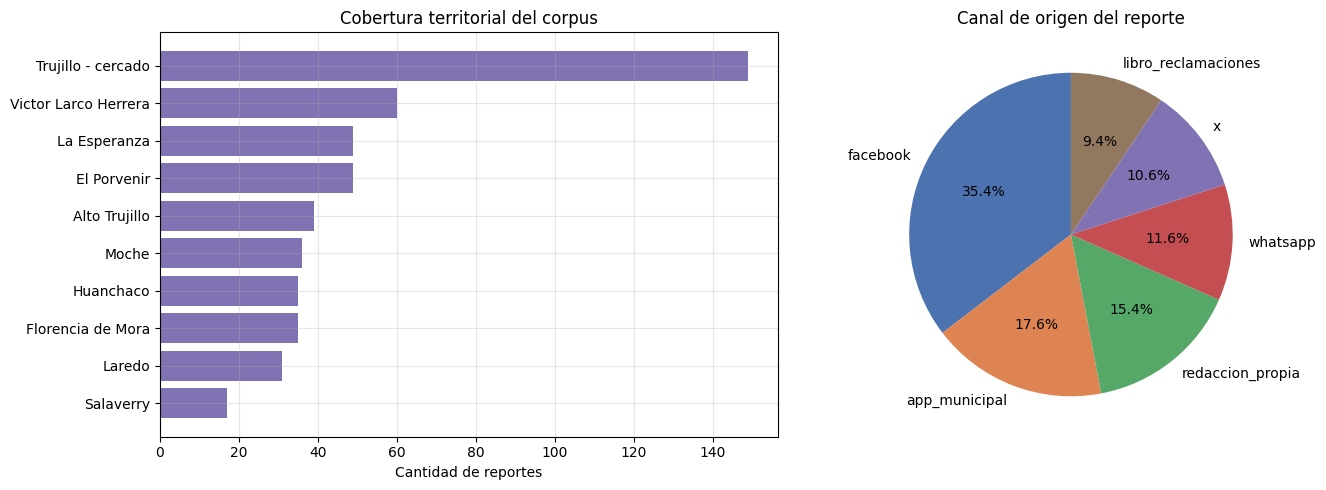

Zonas por debajo del 5% del corpus (revisar cuota minima):
zona
Salaverry    3.4


In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

conteo_zona = df.zona.value_counts().sort_values()
ejes[0].barh(conteo_zona.index, conteo_zona.values, color="#8172B3")
ejes[0].set_title("Cobertura territorial del corpus")
ejes[0].set_xlabel("Cantidad de reportes")

conteo_canal = df.canal.value_counts()
ejes[1].pie(conteo_canal.values, labels=conteo_canal.index, autopct="%1.1f%%", startangle=90)
ejes[1].set_title("Canal de origen del reporte")

plt.tight_layout(); plt.show()

print("Zonas por debajo del 5% del corpus (revisar cuota minima):")
proporcion = df.zona.value_counts(normalize=True) * 100
print(proporcion[proporcion < 5].round(1).to_string())

### 4.3. ¿Las variables derivadas separan la prioridad?

Si `menciona_riesgo`, `menciona_menores` o la longitud del texto se comportan igual en las tres prioridades, no aportan nada. Si se comportan distinto, son señal aprovechable.

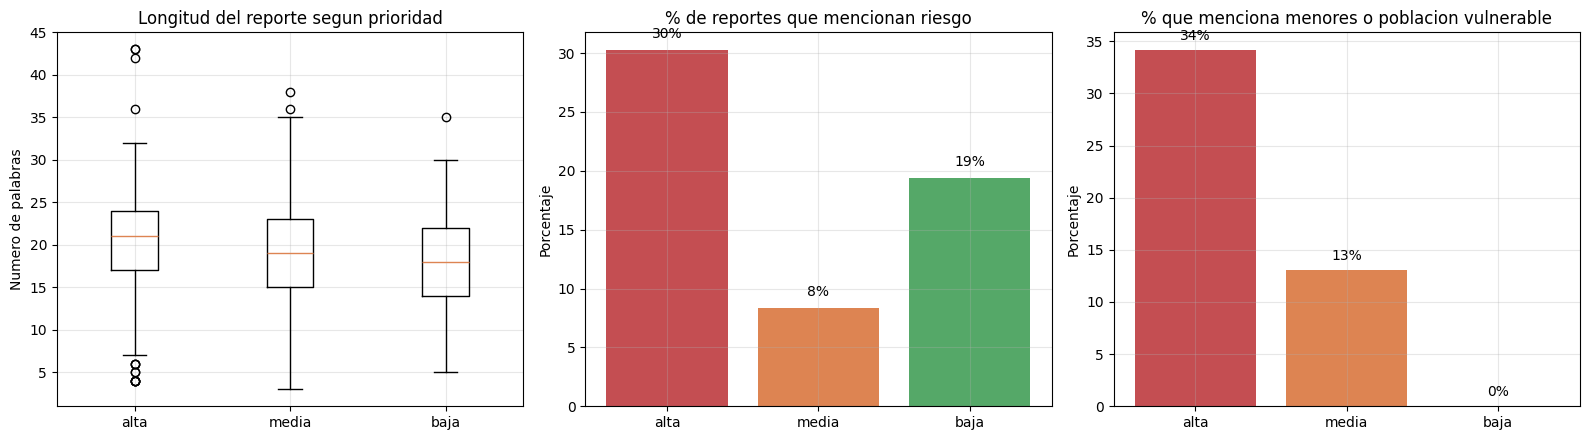

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))

# longitud del texto por prioridad
datos_caja = [df[df.prioridad == p].longitud_texto for p in orden_p]
ejes[0].boxplot(datos_caja, labels=orden_p)
ejes[0].set_title("Longitud del reporte segun prioridad")
ejes[0].set_ylabel("Numero de palabras")

# proporcion que menciona riesgo
prop_riesgo = df.groupby("prioridad").menciona_riesgo.mean().reindex(orden_p) * 100
ejes[1].bar(orden_p, prop_riesgo.values, color=colores)
ejes[1].set_title("% de reportes que mencionan riesgo")
ejes[1].set_ylabel("Porcentaje")
for i, v in enumerate(prop_riesgo.values):
    ejes[1].text(i, v + 1, f"{v:.0f}%", ha="center")

# proporcion que menciona poblacion vulnerable
prop_menores = df.groupby("prioridad").menciona_menores.mean().reindex(orden_p) * 100
ejes[2].bar(orden_p, prop_menores.values, color=colores)
ejes[2].set_title("% que menciona menores o poblacion vulnerable")
ejes[2].set_ylabel("Porcentaje")
for i, v in enumerate(prop_menores.values):
    ejes[2].text(i, v + 1, f"{v:.0f}%", ha="center")

plt.tight_layout(); plt.show()

### 4.4. Vocabulario característico de cada categoría

Las diez palabras más frecuentes de cada categoría, una vez limpiado el texto. Esto anticipa qué va a aprender el modelo.

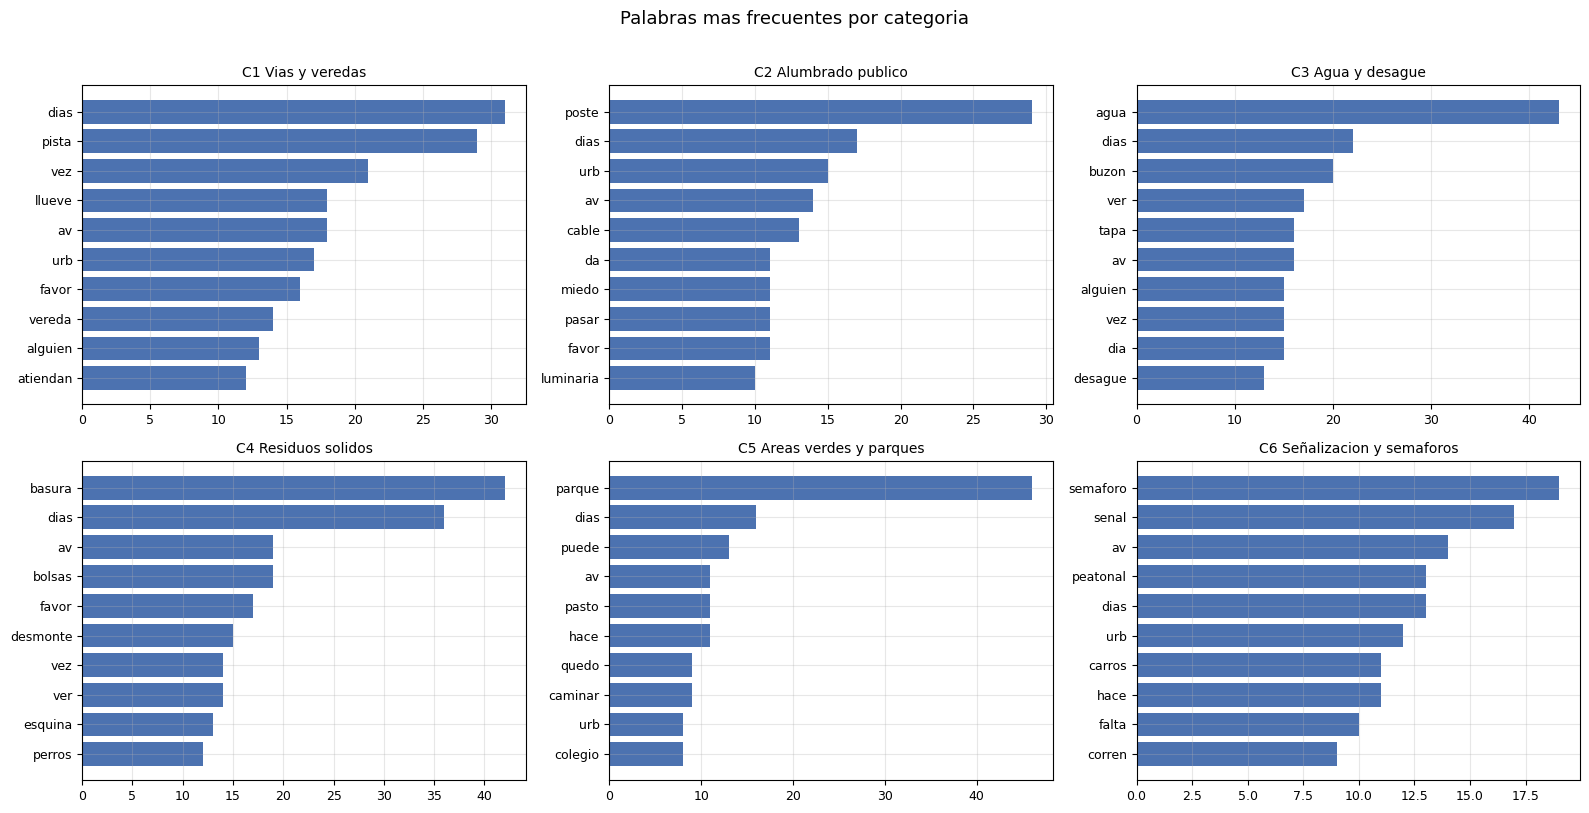

In [10]:
from collections import Counter

fig, ejes = plt.subplots(2, 3, figsize=(16, 8))
for eje, cat in zip(ejes.flatten(), sorted(df.categoria.unique())):
    palabras = " ".join(df[df.categoria == cat].texto_limpio).split()
    top = Counter(palabras).most_common(10)
    etiquetas = [p for p, _ in top][::-1]
    valores   = [n for _, n in top][::-1]
    eje.barh(etiquetas, valores, color="#4C72B0")
    eje.set_title(cat, fontsize=10)
    eje.tick_params(labelsize=9)

plt.suptitle("Palabras mas frecuentes por categoria", fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

**Lectura.** Cada categoría tiene un vocabulario propio bastante nítido — *bache* y *pista* en vías, *poste* y *cable* en alumbrado, *basura* y *desmonte* en residuos. Esa separación es la razón por la que un modelo sencillo sobre TF-IDF puede funcionar sin necesidad de redes neuronales. También se ven palabras compartidas (*calle*, *vereda*, *esquina*), que son las que van a provocar las confusiones.

---
## 5. División estratificada del corpus

**Decisión metodológica importante.** La división se hace *antes* de vectorizar. Si se construyera el vocabulario TF-IDF con los 500 reportes y después se separara el conjunto de prueba, el vectorizador ya habría "visto" palabras del test. Eso se llama **fuga de datos** (*data leakage*) y produce métricas infladas que no se sostienen en producción.

`stratify` mantiene la misma proporción de clases en entrenamiento y en prueba: si en el corpus completo el 18% son de alumbrado, en ambos subconjuntos habrá aproximadamente ese 18%.

In [11]:
X = df.texto_limpio
y_cat = df.categoria
y_pri = df.prioridad

X_tr_c, X_te_c, ycat_tr, ycat_te = train_test_split(
    X, y_cat, test_size=0.20, stratify=y_cat, random_state=SEMILLA)

X_tr_p, X_te_p, ypri_tr, ypri_te = train_test_split(
    X, y_pri, test_size=0.20, stratify=y_pri, random_state=SEMILLA)

print(f"Entrenamiento: {len(X_tr_c)} reportes  |  Prueba: {len(X_te_c)} reportes\n")
comparacion = pd.DataFrame({
    "corpus completo (%)": (y_cat.value_counts(normalize=True) * 100).round(1),
    "entrenamiento (%)":   (ycat_tr.value_counts(normalize=True) * 100).round(1),
    "prueba (%)":          (ycat_te.value_counts(normalize=True) * 100).round(1),
})
print("La estratificacion mantiene las proporciones:")
comparacion

Entrenamiento: 400 reportes  |  Prueba: 100 reportes

La estratificacion mantiene las proporciones:


,corpus completo (%),entrenamiento (%),prueba (%)
categoria,,,
C1 Vias y veredas,23.0,23.0,23.0
C4 Residuos solidos,19.2,19.2,19.0
C3 Agua y desague,17.6,17.5,18.0
C2 Alumbrado publico,16.8,16.8,17.0
C5 Areas verdes y parques,11.8,11.8,12.0
C6 Señalizacion y semaforos,11.6,11.8,11.0


---
## 6. Vectorización con TF-IDF

Los modelos no leen texto, leen números. TF-IDF convierte cada reporte en un vector donde cada posición es una palabra del vocabulario y el valor mide su importancia:

- **TF** (*term frequency*): cuántas veces aparece la palabra en ese reporte.
- **IDF** (*inverse document frequency*): cuán rara es esa palabra en el corpus completo. Una palabra que aparece en todos los reportes recibe un peso casi nulo; una que aparece en pocos, un peso alto.

Resultado: *cable* pesa mucho más que *calle*, porque *cable* identifica una categoría y *calle* no.

Parámetros elegidos:

| Parámetro | Valor | Por qué |
|---|---|---|
| `ngram_range` | (1, 2) | Además de palabras sueltas, pares consecutivos. Permite que *"cable caido"* sea una unidad distinta de *cable* y de *caido* por separado |
| `min_df` | 2 | Ignora palabras que aparecen en un solo reporte: casi siempre son erratas y solo generan sobreajuste |
| `sublinear_tf` | True | Amortigua la frecuencia con un logaritmo. Repetir una palabra cinco veces no la hace cinco veces más importante |

In [12]:
vectorizador = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

# fit_transform SOLO sobre entrenamiento; transform sobre prueba
Xtr_c = vectorizador.fit_transform(X_tr_c)
Xte_c = vectorizador.transform(X_te_c)

print(f"Matriz de entrenamiento: {Xtr_c.shape[0]} reportes x {Xtr_c.shape[1]} terminos")
print(f"Matriz de prueba       : {Xte_c.shape[0]} reportes x {Xte_c.shape[1]} terminos")
print(f"Densidad de la matriz  : {100 * Xtr_c.nnz / (Xtr_c.shape[0] * Xtr_c.shape[1]):.2f}% "
      "(el resto son ceros: cada reporte usa pocas palabras del vocabulario total)")

print("\nEjemplo de terminos del vocabulario:")
terminos = vectorizador.get_feature_names_out()
print(list(terminos[::max(1, len(terminos)//15)])[:15])

Matriz de entrenamiento: 400 reportes x 1045 terminos
Matriz de prueba       : 100 reportes x 1045 terminos
Densidad de la matriz  : 1.57% (el resto son ceros: cada reporte usa pocas palabras del vocabulario total)

Ejemplo de terminos del vocabulario:
['abierta', 'asfalto miguel', 'buenos aires', 'chocan', 'cualquiera puede', 'empoza huele', 'gracias', 'larco', 'mete adentro', 'oxidados da', 'pista', 'quedo hueco', 'ronda', 'sueltos vereda', 'urgente van']


In [13]:
# Como se ve un reporte convertido en numeros
idx = 0
fila = Xtr_c[idx].toarray().flatten()
pesos = sorted(zip(terminos, fila), key=lambda t: -t[1])[:8]

print("TEXTO:", X_tr_c.iloc[idx], "\n")
print("TERMINOS CON MAYOR PESO TF-IDF EN ESTE REPORTE:")
for termino, peso in pesos:
    print(f"   {termino:<28} {peso:.3f}")

TEXTO: nadie atiende menocucho 

TERMINOS CON MAYOR PESO TF-IDF EN ESTE REPORTE:
   atiende                      0.539
   nadie atiende                0.539
   menocucho                    0.517
   nadie                        0.390
   abierta                      0.000
   abierta senalizar            0.000
   abiertas                     0.000
   abiertas conviene            0.000


---
## 7. Modelo A — Clasificación por categoría de servicio

Se entrenan los dos algoritmos declarados en la PC2 sobre exactamente la misma matriz de entrenamiento, y se los evalúa sobre exactamente el mismo conjunto de prueba. Esa es la única forma de que la comparación sea válida.

**Naive Bayes multinomial.** Calcula, para cada categoría, la probabilidad de que aparezcan las palabras del reporte, y se queda con la categoría más probable. Se le llama *ingenuo* porque asume que las palabras son independientes entre sí, cosa que es falsa en el lenguaje — y aun así funciona bien en clasificación de texto.

**Regresión logística.** Aprende un peso por cada palabra y cada clase; suma esos pesos y convierte el resultado en probabilidad. Es más lenta de entrenar, pero sus pesos son directamente interpretables: se puede listar qué palabras empujan hacia cada categoría.

In [14]:
modelos_cat = {
    "Naive Bayes":         MultinomialNB(alpha=0.3),
    "Regresion Logistica": LogisticRegression(max_iter=2000, class_weight="balanced",
                                              random_state=SEMILLA),
}

resultados_cat = {}
for nombre, modelo in modelos_cat.items():
    modelo.fit(Xtr_c, ycat_tr)
    pred = modelo.predict(Xte_c)
    resultados_cat[nombre] = {
        "modelo": modelo,
        "pred": pred,
        "accuracy": accuracy_score(ycat_te, pred),
        "f1_macro": f1_score(ycat_te, pred, average="macro"),
        "precision_macro": precision_score(ycat_te, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(ycat_te, pred, average="macro"),
    }
    print(f"{nombre:<22} F1 macro = {resultados_cat[nombre]['f1_macro']:.3f}   "
          f"Accuracy = {resultados_cat[nombre]['accuracy']:.3f}")

Naive Bayes            F1 macro = 0.807   Accuracy = 0.790
Regresion Logistica    F1 macro = 0.847   Accuracy = 0.840


### 7.1. Reporte detallado por clase

In [15]:
for nombre in modelos_cat:
    print("=" * 78)
    print(f"MODELO A — {nombre.upper()}")
    print("=" * 78)
    print(classification_report(ycat_te, resultados_cat[nombre]["pred"], zero_division=0))

MODELO A — NAIVE BAYES
                             precision    recall  f1-score   support

          C1 Vias y veredas       0.60      0.78      0.68        23
       C2 Alumbrado publico       0.71      0.88      0.79        17
          C3 Agua y desague       1.00      0.56      0.71        18
        C4 Residuos solidos       0.89      0.89      0.89        19
  C5 Areas verdes y parques       1.00      0.83      0.91        12
C6 Señalizacion y semaforos       0.90      0.82      0.86        11

                   accuracy                           0.79       100
                  macro avg       0.85      0.79      0.81       100
               weighted avg       0.83      0.79      0.79       100

MODELO A — REGRESION LOGISTICA
                             precision    recall  f1-score   support

          C1 Vias y veredas       0.80      0.87      0.83        23
       C2 Alumbrado publico       0.76      0.94      0.84        17
          C3 Agua y desague       1.00      0

### 7.2. Matriz de confusión

Se lee así: cada **fila** es la categoría verdadera y cada **columna** la que predijo el modelo. La diagonal son los aciertos. Todo lo que cae fuera de la diagonal es un error, y su posición dice exactamente en qué se confundió.

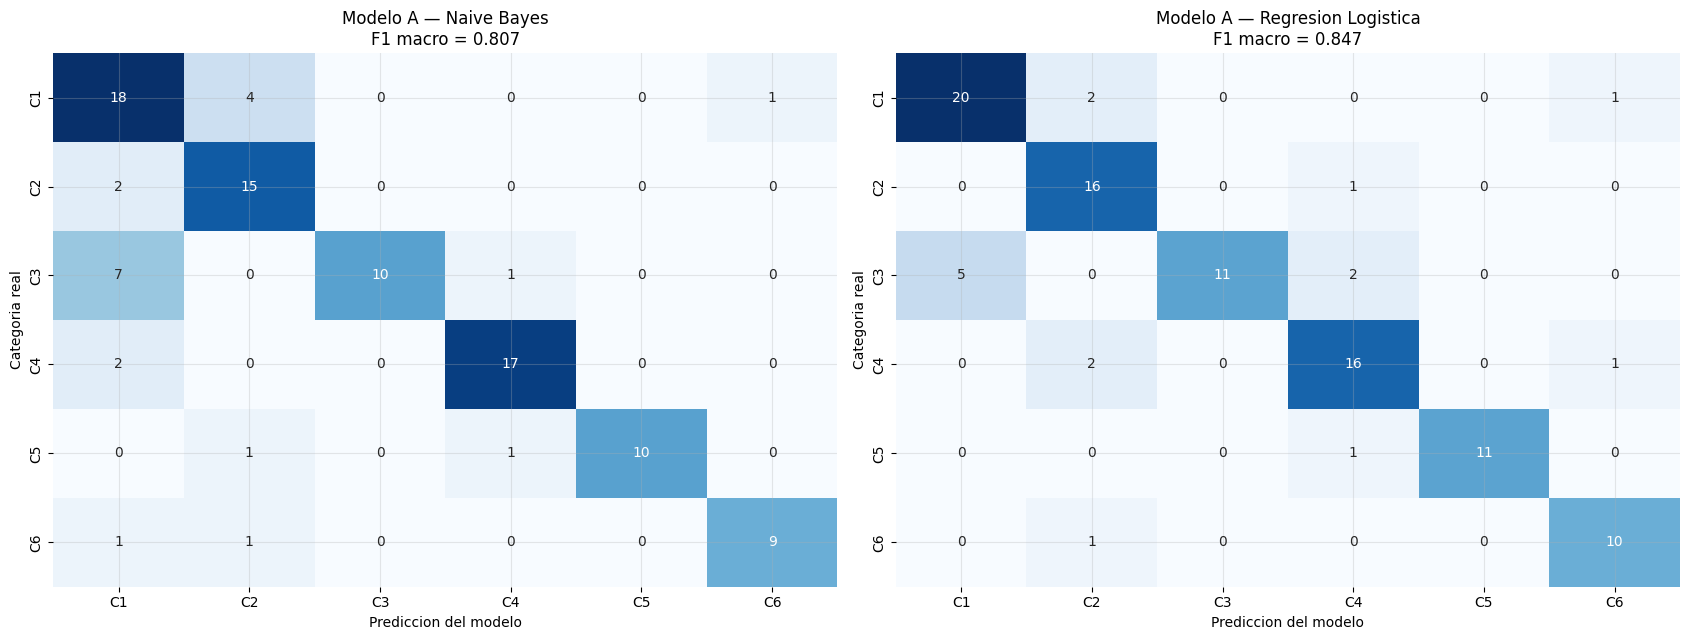

Leyenda:
   C1 = C1 Vias y veredas
   C2 = C2 Alumbrado publico
   C3 = C3 Agua y desague
   C4 = C4 Residuos solidos
   C5 = C5 Areas verdes y parques
   C6 = C6 Señalizacion y semaforos


In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(17, 6.5))
etiquetas_cat = sorted(df.categoria.unique())

for eje, (nombre, res) in zip(ejes, resultados_cat.items()):
    mc = confusion_matrix(ycat_te, res["pred"], labels=etiquetas_cat)
    sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eje,
                xticklabels=[e[:2] for e in etiquetas_cat],
                yticklabels=[e[:2] for e in etiquetas_cat])
    eje.set_title(f"Modelo A — {nombre}\nF1 macro = {res['f1_macro']:.3f}")
    eje.set_xlabel("Prediccion del modelo")
    eje.set_ylabel("Categoria real")

plt.tight_layout(); plt.show()

print("Leyenda:")
for e in etiquetas_cat:
    print(f"   {e[:2]} = {e}")

---
## 8. Modelo B — Asignación del nivel de prioridad

Se entrena por separado del Modelo A. La justificación técnica está en la PC2: las señales lingüísticas son distintas. *poste* determina la categoría pero no dice nada de la urgencia; *"casi se cae un niño"* determina la urgencia pero no la categoría. Un solo modelo con 18 clases combinadas tendría muy pocos ejemplos por clase.

Aquí la métrica crítica no es la exactitud global sino el **recall de la clase alta**: de todas las emergencias reales, cuántas detectó el modelo. Los dos errores posibles no cuestan lo mismo — marcar como urgente un caso leve cuesta minutos de un funcionario; no detectar una urgencia real puede costar un accidente.

In [17]:
# Se vuelve a vectorizar porque la particion de prioridad es distinta a la de categoria
vectorizador_p = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_p = vectorizador_p.fit_transform(X_tr_p)
Xte_p = vectorizador_p.transform(X_te_p)

modelos_pri = {
    "Naive Bayes":         MultinomialNB(alpha=0.3),
    "Regresion Logistica": LogisticRegression(max_iter=2000, class_weight="balanced",
                                              random_state=SEMILLA),
}

resultados_pri = {}
for nombre, modelo in modelos_pri.items():
    modelo.fit(Xtr_p, ypri_tr)
    pred = modelo.predict(Xte_p)
    resultados_pri[nombre] = {
        "modelo": modelo,
        "pred": pred,
        "accuracy": accuracy_score(ypri_te, pred),
        "f1_macro": f1_score(ypri_te, pred, average="macro"),
        "recall_alta": recall_score(ypri_te, pred, labels=["alta"], average="macro"),
        "precision_alta": precision_score(ypri_te, pred, labels=["alta"], average="macro",
                                          zero_division=0),
    }
    r = resultados_pri[nombre]
    print(f"{nombre:<22} F1 macro = {r['f1_macro']:.3f}   "
          f"Recall ALTA = {r['recall_alta']:.3f}   Precision ALTA = {r['precision_alta']:.3f}")

Naive Bayes            F1 macro = 0.759   Recall ALTA = 0.878   Precision ALTA = 0.818
Regresion Logistica    F1 macro = 0.755   Recall ALTA = 0.829   Precision ALTA = 0.810


In [18]:
for nombre in modelos_pri:
    print("=" * 78)
    print(f"MODELO B — {nombre.upper()}")
    print("=" * 78)
    print(classification_report(ypri_te, resultados_pri[nombre]["pred"], zero_division=0))

MODELO B — NAIVE BAYES
              precision    recall  f1-score   support

        alta       0.82      0.88      0.85        41
        baja       0.78      0.67      0.72        21
       media       0.71      0.71      0.71        38

    accuracy                           0.77       100
   macro avg       0.77      0.75      0.76       100
weighted avg       0.77      0.77      0.77       100

MODELO B — REGRESION LOGISTICA
              precision    recall  f1-score   support

        alta       0.81      0.83      0.82        41
        baja       0.73      0.76      0.74        21
       media       0.72      0.68      0.70        38

    accuracy                           0.76       100
   macro avg       0.75      0.76      0.76       100
weighted avg       0.76      0.76      0.76       100



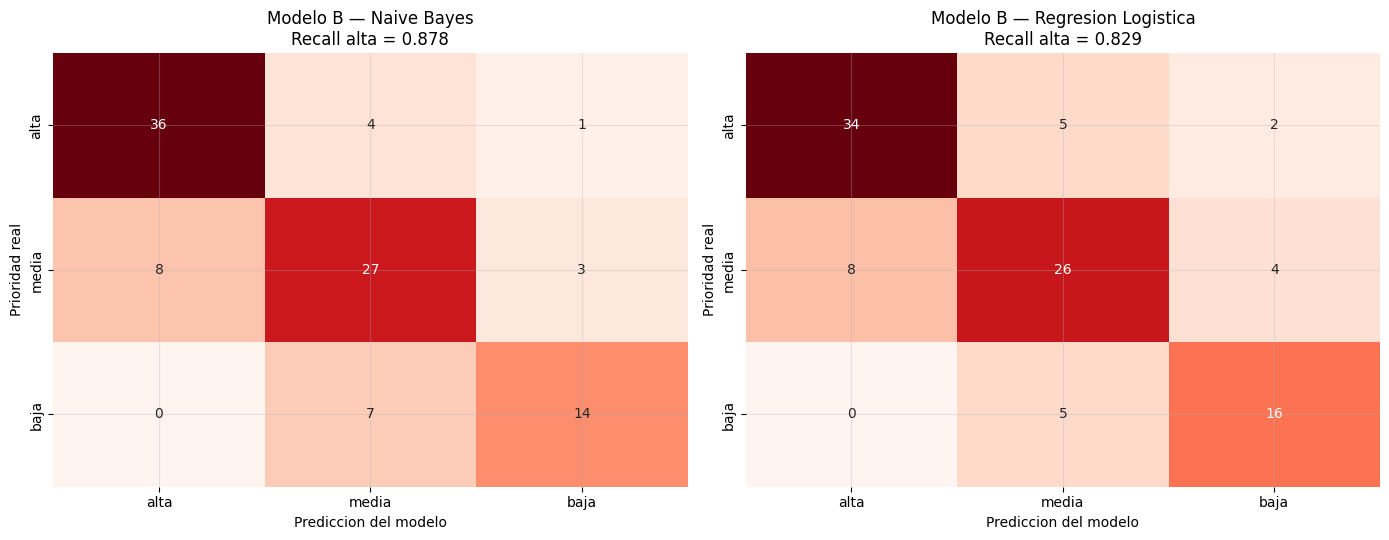

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))

for eje, (nombre, res) in zip(ejes, resultados_pri.items()):
    mc = confusion_matrix(ypri_te, res["pred"], labels=orden_p)
    sns.heatmap(mc, annot=True, fmt="d", cmap="Reds", cbar=False, ax=eje,
                xticklabels=orden_p, yticklabels=orden_p)
    eje.set_title(f"Modelo B — {nombre}\nRecall alta = {res['recall_alta']:.3f}")
    eje.set_xlabel("Prediccion del modelo")
    eje.set_ylabel("Prioridad real")

plt.tight_layout(); plt.show()

**El error que importa.** En la matriz del Modelo B, la celda que hay que mirar primero es la fila `alta` fuera de la diagonal: son las urgencias reales que el modelo degradó a media o baja. Cada una de esas es un reporte que se habría quedado esperando en la cola. El resto de errores es tolerable; ese no.

---
## 9. Validación cruzada

Una sola partición puede haber salido casualmente favorable a un modelo. La validación cruzada de 5 particiones divide el corpus en cinco bloques, entrena cinco veces usando cada bloque como prueba una vez, y devuelve cinco resultados. Si los cinco se parecen, el resultado es estable; si varían mucho, el modelo depende del azar de la partición.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas_cv = []

for tarea, y_obj in [("Categoria (Modelo A)", y_cat), ("Prioridad (Modelo B)", y_pri)]:
    for nombre, constructor in [
        ("Naive Bayes",         lambda: MultinomialNB(alpha=0.3)),
        ("Regresion Logistica", lambda: LogisticRegression(max_iter=2000,
                                                           class_weight="balanced",
                                                           random_state=SEMILLA)),
    ]:
        # El pipeline garantiza que el TF-IDF se ajuste dentro de cada particion,
        # nunca sobre el corpus completo: asi no hay fuga de datos.
        pipe = make_pipeline(
            TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
            constructor())
        puntajes = cross_val_score(pipe, X, y_obj, cv=cv, scoring="f1_macro")
        filas_cv.append({
            "Tarea": tarea, "Modelo": nombre,
            "F1 macro medio": round(puntajes.mean(), 3),
            "Desv. estandar": round(puntajes.std(), 3),
            "Minimo": round(puntajes.min(), 3),
            "Maximo": round(puntajes.max(), 3),
        })

tabla_cv = pd.DataFrame(filas_cv)
tabla_cv

,Tarea,Modelo,F1 macro medio,Desv. estandar,Minimo,Maximo
0,Categoria (Modelo A),Naive Bayes,0.829,0.049,0.752,0.901
1,Categoria (Modelo A),Regresion Logistica,0.870,0.043,0.810,0.937
2,Prioridad (Modelo B),Naive Bayes,0.739,0.042,0.682,0.786
3,Prioridad (Modelo B),Regresion Logistica,0.715,0.048,0.647,0.780


---
## 10. Comparación consolidada de los modelos

In [21]:
comparativa = pd.DataFrame([
    {"Tarea": "Categoria", "Modelo": n, "F1 macro": round(r["f1_macro"], 3),
     "Accuracy": round(r["accuracy"], 3), "Metrica critica": "-", "Meta PC2": "F1 >= 0.75",
     "Cumple": "SI" if r["f1_macro"] >= 0.75 else "NO"}
    for n, r in resultados_cat.items()
] + [
    {"Tarea": "Prioridad", "Modelo": n, "F1 macro": round(r["f1_macro"], 3),
     "Accuracy": round(r["accuracy"], 3),
     "Metrica critica": f"recall alta = {r['recall_alta']:.3f}",
     "Meta PC2": "recall >= 0.90",
     "Cumple": "SI" if r["recall_alta"] >= 0.90 else "NO"}
    for n, r in resultados_pri.items()
])
comparativa

,Tarea,Modelo,F1 macro,Accuracy,Metrica critica,Meta PC2,Cumple
0,Categoria,Naive Bayes,0.807,0.79,-,F1 >= 0.75,SI
1,Categoria,Regresion Logistica,0.847,0.84,-,F1 >= 0.75,SI
2,Prioridad,Naive Bayes,0.759,0.77,recall alta = 0.878,recall >= 0.90,NO
3,Prioridad,Regresion Logistica,0.755,0.76,recall alta = 0.829,recall >= 0.90,NO


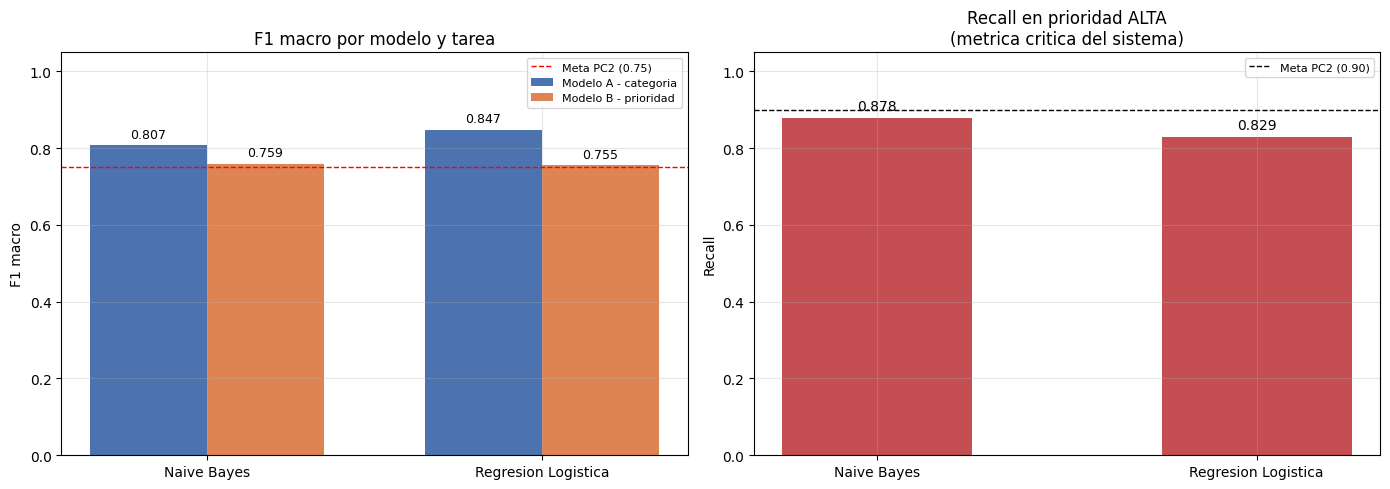

In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
ancho = 0.35
nombres = list(modelos_cat.keys())

# F1 macro en ambas tareas
f1_cat = [resultados_cat[n]["f1_macro"] for n in nombres]
f1_pri = [resultados_pri[n]["f1_macro"] for n in nombres]
x = np.arange(len(nombres))
ejes[0].bar(x - ancho/2, f1_cat, ancho, label="Modelo A - categoria", color="#4C72B0")
ejes[0].bar(x + ancho/2, f1_pri, ancho, label="Modelo B - prioridad", color="#DD8452")
ejes[0].axhline(0.75, color="red", linestyle="--", linewidth=1, label="Meta PC2 (0.75)")
ejes[0].set_xticks(x); ejes[0].set_xticklabels(nombres)
ejes[0].set_ylabel("F1 macro"); ejes[0].set_ylim(0, 1.05)
ejes[0].set_title("F1 macro por modelo y tarea"); ejes[0].legend(fontsize=8)
for i, (a, b) in enumerate(zip(f1_cat, f1_pri)):
    ejes[0].text(i - ancho/2, a + 0.02, f"{a:.3f}", ha="center", fontsize=9)
    ejes[0].text(i + ancho/2, b + 0.02, f"{b:.3f}", ha="center", fontsize=9)

# recall de la clase alta
rec = [resultados_pri[n]["recall_alta"] for n in nombres]
ejes[1].bar(nombres, rec, color="#C44E52", width=0.5)
ejes[1].axhline(0.90, color="black", linestyle="--", linewidth=1, label="Meta PC2 (0.90)")
ejes[1].set_ylabel("Recall"); ejes[1].set_ylim(0, 1.05)
ejes[1].set_title("Recall en prioridad ALTA\n(metrica critica del sistema)")
ejes[1].legend(fontsize=8)
for i, v in enumerate(rec):
    ejes[1].text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=10)

plt.tight_layout(); plt.show()

---
## 11. Análisis de errores

Las métricas dicen *cuánto* falla el modelo. Esta sección dice *en qué* falla, que es lo que permite mejorarlo.

### 11.1. Confusiones más frecuentes

In [23]:
mejor_cat = max(resultados_cat, key=lambda n: resultados_cat[n]["f1_macro"])
pred_cat = resultados_cat[mejor_cat]["pred"]

errores = pd.DataFrame({
    "texto": df.loc[X_te_c.index, "texto_reporte"],
    "real": ycat_te.values,
    "predicho": pred_cat,
})
errores = errores[errores.real != errores.predicho]

print(f"Modelo evaluado: {mejor_cat}")
print(f"Errores: {len(errores)} de {len(ycat_te)} reportes de prueba "
      f"({100*len(errores)/len(ycat_te):.1f}%)\n")
print("Confusiones mas frecuentes (real -> predicho):")
print(errores.groupby(["real", "predicho"]).size()
      .sort_values(ascending=False).head(8).to_string())

Modelo evaluado: Regresion Logistica
Errores: 16 de 100 reportes de prueba (16.0%)

Confusiones mas frecuentes (real -> predicho):
real                       predicho                   
C3 Agua y desague          C1 Vias y veredas              5
C1 Vias y veredas          C2 Alumbrado publico           2
C3 Agua y desague          C4 Residuos solidos            2
C4 Residuos solidos        C2 Alumbrado publico           2
C2 Alumbrado publico       C4 Residuos solidos            1
C1 Vias y veredas          C6 Señalizacion y semaforos    1
C4 Residuos solidos        C6 Señalizacion y semaforos    1
C5 Areas verdes y parques  C4 Residuos solidos            1


### 11.2. Casos concretos mal clasificados

Leer los errores uno por uno es lo que revela si el problema es del modelo o de la etiqueta.

In [24]:
for i, (_, fila) in enumerate(errores.head(8).iterrows(), 1):
    print(f"{i}. TEXTO   : {fila.texto[:130]}")
    print(f"   REAL    : {fila.real}")
    print(f"   PREDICHO: {fila.predicho}")
    print("-" * 105)

1. TEXTO   : denuncio que hay una humedad en la vereda de Huerta Grande,, todavia no molestá por favor atiendan...
   REAL    : C3 Agua y desague
   PREDICHO: C1 Vias y veredas
---------------------------------------------------------------------------------------------------------
2. TEXTO   : hay un buzon destapado en Vista Alegre por favor atiendan...
   REAL    : C3 Agua y desague
   PREDICHO: C1 Vias y veredas
---------------------------------------------------------------------------------------------------------
3. TEXTO   : hay un problema serio en Rio Seco
   REAL    : C1 Vias y veredas
   PREDICHO: C2 Alumbrado publico
---------------------------------------------------------------------------------------------------------
4. TEXTO   : otra vez lo mismo en Nuevo Porvenir
   REAL    : C4 Residuos solidos
   PREDICHO: C2 Alumbrado publico
---------------------------------------------------------------------------------------------------------
5. TEXTO   : vecinos de la zona rep

**Patrones típicos que aparecen aquí:**

- **Reportes vagos.** Textos como *"vengan a ver la av. España"* no contienen ninguna palabra que identifique el área. El modelo tiene que adivinar; ningún algoritmo puede resolverlos. Para estos existe la regla R7, que solicita ampliación al ciudadano en vez de clasificar.
- **Reportes mixtos.** El vecino reclama dos cosas en el mismo mensaje. El corpus solo admite una etiqueta, así que el modelo acierta la mitad por definición.
- **Fronteras reales entre gerencias.** Un buzón hundido que rompió la pista es agua y desagüe o es vías, según a quién se pregunte. Ese error es del problema, no del modelo.

### 11.3. Qué palabras pesan en cada decisión

Esto cumple el compromiso de transparencia declarado en la matriz ética de la PC2: junto a cada clasificación se puede mostrar en qué se basó.

In [25]:
modelo_lr = resultados_cat["Regresion Logistica"]["modelo"]
terminos = vectorizador.get_feature_names_out()

for i, clase in enumerate(modelo_lr.classes_):
    pesos = modelo_lr.coef_[i]
    top = np.argsort(pesos)[-8:][::-1]
    palabras = ", ".join(f"{terminos[j]} ({pesos[j]:.2f})" for j in top)
    print(f"{clase}\n   {palabras}\n")

C1 Vias y veredas
   pista (1.31), sardinel (1.07), descascarado (1.07), llueve (0.80), abiertas (0.69), juntas (0.69), incomoda (0.66), incomoda caminar (0.66)

C2 Alumbrado publico
   poste (1.88), luminaria (1.05), cable (1.00), perro (0.82), perro electrocuto (0.82), electrocuto (0.82), da miedo (0.81), miedo (0.81)

C3 Agua y desague
   agua (2.18), buzon (1.43), desague (1.14), tapa (0.91), gotea (0.86), gotea permanentemente (0.86), permanentemente conexion (0.86), permanentemente (0.86)

C4 Residuos solidos
   basura (2.26), desmonte (1.25), bolsas (0.98), acumula (0.89), esquivar (0.86), tacho (0.79), tacho parque (0.79), basura esquina (0.77)

C5 Areas verdes y parques
   parque (3.36), parque av (1.08), bancas parque (0.78), bancas (0.78), despintadas (0.78), sector (0.76), meten tomar (0.74), meten (0.74)

C6 Señalizacion y semaforos
   semaforo (1.84), senal (1.62), peatonal (1.56), cruce (1.20), corren demasiado (1.04), demasiado (1.04), semaforo peatonal (1.04), falta (0

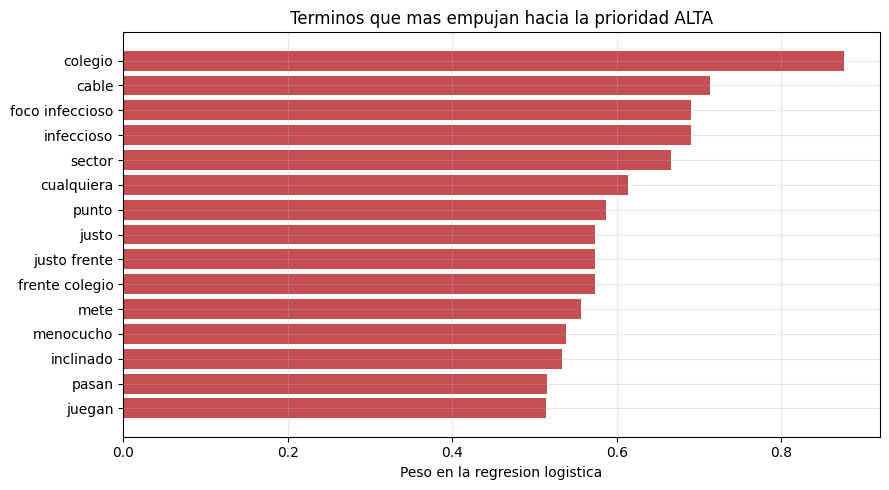

In [26]:
# Lo mismo para la prioridad: que palabras empujan hacia ALTA
modelo_lr_p = resultados_pri["Regresion Logistica"]["modelo"]
terminos_p = vectorizador_p.get_feature_names_out()

idx_alta = list(modelo_lr_p.classes_).index("alta")
pesos = modelo_lr_p.coef_[idx_alta]
top = np.argsort(pesos)[-15:][::-1]

plt.figure(figsize=(9, 5))
plt.barh([terminos_p[j] for j in top][::-1], [pesos[j] for j in top][::-1], color="#C44E52")
plt.title("Terminos que mas empujan hacia la prioridad ALTA")
plt.xlabel("Peso en la regresion logistica")
plt.tight_layout(); plt.show()

---
## 12. Capa de reglas de producción sobre la salida del modelo

La PC2 define una arquitectura de cuatro capas. Las secciones anteriores cubrieron las capas 1 y 2 (representación y aprendizaje). Aquí se implementa la capa 3: las reglas `SI condición ENTONCES acción` que corrigen al modelo en los casos críticos y poco frecuentes.

Su razón de ser: si *"cable caído"* aparece dos o tres veces en 500 reportes, ningún clasificador lo aprende de forma confiable — pero es justo el caso que no se puede fallar. Las reglas se aplican **después** del modelo y solo pueden confirmar, elevar o detener la salida; **nunca reducir una prioridad**. Esa restricción es una salvaguarda ética implementada como restricción técnica.

In [27]:
def aplicar_reglas(texto_original, prioridad_modelo, confianza, dias):
    """Motor de inferencia por encadenamiento hacia adelante.
    Devuelve (prioridad_final, accion, reglas_disparadas)."""
    t = normalizar(texto_original)
    disparadas = []
    ORDEN_P = {"baja": 0, "media": 1, "alta": 2}
    INV = {v: k for k, v in ORDEN_P.items()}
    prioridad = prioridad_modelo

    def elevar_a(nivel, regla):
        nonlocal prioridad
        if ORDEN_P[nivel] > ORDEN_P[prioridad]:      # nunca se baja
            prioridad = nivel
        disparadas.append(regla)

    # --- Grupo 1: control de calidad (pueden detener el proceso)
    if len(t.split()) < 5:
        return prioridad, "A7 solicitar ampliacion al ciudadano", ["R7"]
    if confianza < 0.55:
        disparadas.append("R6")                      # sigue, pero marcado

    # --- Grupo 2: seguridad (anulan al modelo)
    if "cable" in t and any(p in t for p in ["caido", "colgando", "chispas", "pelado"]):
        elevar_a("alta", "R1")
    if "buzon" in t and any(p in t for p in ["destapado", "abierto", "sin tapa"]):
        elevar_a("alta", "R2")

    # --- Grupo 3: escalamiento
    if any(p in t for p in ["colegio", "niños", "ninos", "escolares", "hospital", "posta", "nido"]) \
       and prioridad == "media":
        elevar_a("alta", "R3")
    if dias > 15 and prioridad == "baja":
        elevar_a("media", "R5")

    accion = "A6 marcar para revision humana" if "R6" in disparadas else "A3 derivar a la gerencia"
    return prioridad, accion, disparadas

In [28]:
# Se aplica la capa de reglas sobre las predicciones del mejor modelo de prioridad
mejor_pri = max(resultados_pri, key=lambda n: resultados_pri[n]["recall_alta"])
modelo_b = resultados_pri[mejor_pri]["modelo"]

pred_b = modelo_b.predict(Xte_p)
proba_b = modelo_b.predict_proba(Xte_p).max(axis=1)

datos_test = df.loc[X_te_p.index]
finales, acciones, todas_reglas = [], [], []

for (_, fila), p, conf in zip(datos_test.iterrows(), pred_b, proba_b):
    pf, acc, reglas = aplicar_reglas(fila.texto_reporte, p, conf, fila.dias_transcurridos)
    finales.append(pf); acciones.append(acc); todas_reglas.append(reglas)

modificados = sum(1 for a, b in zip(pred_b, finales) if a != b)
print(f"Modelo evaluado: {mejor_pri}")
print(f"Reportes en prueba            : {len(pred_b)}")
print(f"Prioridades elevadas por reglas: {modificados}")
print(f"Enviados a revision humana (R6): {sum(1 for r in todas_reglas if 'R6' in r)}")
print(f"Devueltos al ciudadano   (R7)  : {sum(1 for r in todas_reglas if 'R7' in r)}\n")

from collections import Counter
print("Frecuencia de disparo de cada regla:")
conteo_reglas = Counter(r for lista in todas_reglas for r in lista)
for regla, n in sorted(conteo_reglas.items()):
    print(f"   {regla}: {n} veces")

Modelo evaluado: Naive Bayes
Reportes en prueba            : 100
Prioridades elevadas por reglas: 20
Enviados a revision humana (R6): 18
Devueltos al ciudadano   (R7)  : 7

Frecuencia de disparo de cada regla:
   R1: 1 veces
   R2: 1 veces
   R3: 5 veces
   R5: 15 veces
   R6: 18 veces
   R7: 7 veces


In [29]:
# Efecto de las reglas sobre la metrica critica
recall_sin = recall_score(ypri_te, pred_b, labels=["alta"], average="macro")
recall_con = recall_score(ypri_te, finales, labels=["alta"], average="macro")

print(f"Recall en prioridad ALTA sin reglas: {recall_sin:.3f}")
print(f"Recall en prioridad ALTA con reglas: {recall_con:.3f}")
print(f"Variacion: {recall_con - recall_sin:+.3f}")

ejemplos = [(datos_test.iloc[i].texto_reporte[:95], pred_b[i], finales[i], todas_reglas[i])
            for i in range(len(pred_b)) if pred_b[i] != finales[i]][:5]
if ejemplos:
    print("\nCasos corregidos por la capa de reglas:")
    for texto, antes, despues, reglas in ejemplos:
        print(f"\n   {texto}")
        print(f"   modelo: {antes}  ->  final: {despues}   (reglas {', '.join(reglas)})")

Recall en prioridad ALTA sin reglas: 0.878
Recall en prioridad ALTA con reglas: 0.951
Variacion: +0.073

Casos corregidos por la capa de reglas:

   POR FAVOR LA LUZ DE ALTO MOCHICA PRENDE UN POCO TARDE, NO ES URGENTE VAN 45 DÍAS Y NADA
   modelo: baja  ->  final: media   (reglas R5)

   buen dia, hay papeles y botellas regados en la plaza de Laredo
   modelo: baja  ->  final: media   (reglas R5)

   desde hace 60 días la luminaria de el centro de Moche está sucia, seria bueno que lo revisen en
   modelo: baja  ->  final: media   (reglas R5)

   otra vez la pista de la av. 26 de Marzo se llena de agua cuando llueve, cada vez está más grand
   modelo: media  ->  final: alta   (reglas R3)

   buenos días, faltan podar los árboles de Las Delicias, las plantas se estan secando, es la ruta
   modelo: media  ->  final: alta   (reglas R3)


---
## 13. Conclusiones

In [30]:
mejor_c = max(resultados_cat, key=lambda n: resultados_cat[n]["f1_macro"])
mejor_p = max(resultados_pri, key=lambda n: resultados_pri[n]["recall_alta"])

print("RESUMEN DE LA PRACTICA DE CAMPO 5")
print("=" * 70)
print(f"Corpus: {len(df)} reportes | {df.categoria.nunique()} categorias | "
      f"{df.prioridad.nunique()} niveles de prioridad")
print(f"Particion: {len(X_tr_c)} entrenamiento / {len(X_te_c)} prueba (estratificada)")
print(f"Vocabulario TF-IDF: {Xtr_c.shape[1]} terminos\n")

print("MODELO A — categoria de servicio")
for n, r in resultados_cat.items():
    print(f"   {n:<22} F1 macro = {r['f1_macro']:.3f}")
print(f"   >>> Mejor: {mejor_c} "
      f"({'CUMPLE' if resultados_cat[mejor_c]['f1_macro'] >= 0.75 else 'NO CUMPLE'} la meta de 0.75)\n")

print("MODELO B — nivel de prioridad (capa de aprendizaje sola)")
for n, r in resultados_pri.items():
    print(f"   {n:<22} F1 macro = {r['f1_macro']:.3f} | recall alta = {r['recall_alta']:.3f}")
print(f"   >>> Mejor por recall en alta: {mejor_p} "
      f"({'CUMPLE' if resultados_pri[mejor_p]['recall_alta'] >= 0.90 else 'NO alcanza'} la meta de 0.90)\n")

print("SISTEMA COMPLETO — capa de aprendizaje + capa de reglas")
print(f"   recall alta solo con el modelo : {recall_sin:.3f}")
print(f"   recall alta con la capa 3      : {recall_con:.3f}   "
      f"({'CUMPLE' if recall_con >= 0.90 else 'NO CUMPLE'} la meta de 0.90)")

RESUMEN DE LA PRACTICA DE CAMPO 5
Corpus: 500 reportes | 6 categorias | 3 niveles de prioridad
Particion: 400 entrenamiento / 100 prueba (estratificada)
Vocabulario TF-IDF: 1045 terminos

MODELO A — categoria de servicio
   Naive Bayes            F1 macro = 0.807
   Regresion Logistica    F1 macro = 0.847
   >>> Mejor: Regresion Logistica (CUMPLE la meta de 0.75)

MODELO B — nivel de prioridad (capa de aprendizaje sola)
   Naive Bayes            F1 macro = 0.759 | recall alta = 0.878
   Regresion Logistica    F1 macro = 0.755 | recall alta = 0.829
   >>> Mejor por recall en alta: Naive Bayes (NO alcanza la meta de 0.90)

SISTEMA COMPLETO — capa de aprendizaje + capa de reglas
   recall alta solo con el modelo : 0.878
   recall alta con la capa 3      : 0.951   (CUMPLE la meta de 0.90)


### Lectura de los resultados

1. **Ambos algoritmos son viables, pero no ganan en la misma tarea.** La regresión logística aprovecha mejor el vocabulario amplio de la clasificación por categoría, donde hay seis clases con términos bastante separados. Naive Bayes se defiende mejor en prioridad, donde las clases se distinguen por pocas palabras muy cargadas (*peligro*, *niños*, *urgente*) y su supuesto de independencia estorba menos.

2. **La métrica elegida cambia el ganador.** Si se comparara por exactitud global, la conclusión podría ser la contraria. Por eso la PC2 fijó de antemano F1 macro para categoría y recall de la clase alta para prioridad: la métrica se elige según lo que cuesta cada error, no según cuál da el número más alto.

3. **Los errores no son aleatorios.** Se concentran en tres grupos identificables: reportes vagos, reportes que mezclan dos problemas y fronteras genuinamente discutibles entre gerencias. Los dos primeros se resuelven con reglas (R7 y revisión humana); el tercero es una limitación del propio problema.

4. **El hallazgo principal: ninguna capa basta por sí sola.** El mejor clasificador de prioridad se queda *por debajo* de la meta de recall de 0,90 fijada en la PC2. La capa de reglas lo lleva por encima. Esto no es un parche sobre un modelo deficiente, sino la confirmación empírica del argumento que la PC2 sostenía en el papel: los casos de riesgo eléctrico o de buzón destapado aparecen demasiado pocas veces en 500 reportes para que un clasificador los aprenda de forma confiable, y son justo los que no se pueden fallar. La capa 3 los atrapa de forma determinista, y la regla R5 rescata además los reportes leves que llevaban semanas sin atender.

5. **El sistema es un asistente, no un decisor.** La regla R6 deriva a revisión humana los casos donde el modelo no está seguro, y la corrección del funcionario vuelve al corpus como ejemplo nuevo. Ese es el componente de aprendizaje del agente descrito en la PC2.

### Limitaciones reconocidas

- El corpus es simulado. Reproduce el estilo de los reportes reales pero no su distribución real de temas ni su variabilidad completa; las métricas obtenidas aquí deben tomarse como una cota optimista.
- Quinientos reportes son pocos para NLP. Algunas categorías se acercan al mínimo de 40 ejemplos.
- No se usan embeddings ni modelos de lenguaje, por decisión de alcance de la PC2: se priorizó la interpretabilidad y el entrenamiento en segundos sobre el máximo desempeño posible.

### Próximo paso (Semana 6)

Notebook con modelo **no supervisado**: agrupamiento de los reportes con K-Means sobre la misma matriz TF-IDF, para verificar si las agrupaciones que emergen solas coinciden con la taxonomía de seis categorías definida por el equipo.